# Week 6 — Part-of-Speech Tagging & Stop Words
**Project:** French Environmental Text Intelligence (Group 3, French)

**What this notebook does, in plain words.**
- **POS tagging** labels every word with its grammatical role: noun, verb, adjective… The same word can have several roles (*le **contrôle** des émissions* is a noun, *il **contrôle*** is a verb), so a tagger must use the context.
- **Stop words** are very frequent words with little meaning (*le, de, et, est*). Removing them makes word counts and search more meaningful, but it can also destroy meaning (*ne … pas*!).

We do the four homework tasks of the lecture on **our French corpus**, and we evaluate taggers on a real French **treebank** (Universal Dependencies French-GSD, in CoNLL-U format):

| Section | Homework task |
|---|---|
| 1 | POS-tag a paragraph and list the ambiguous words |
| 2 | Evaluate POS taggers: spaCy, a most-frequent-tag baseline, a rule-based tagger, and NLTK (English only!) |
| 3 | Build a preprocessing function (lowercase, lemmatize, remove stop words and punctuation) |
| 4 | Compare word frequencies before and after stop-word removal |
| 5 | Parse CoNLL-U files with `conllu` and count the UPOS tags |
| 6 | When stop-word removal is dangerous |


## Setup

In [1]:
# !pip install spacy nltk conllu pandas matplotlib
# !python -m spacy download fr_core_news_md
from collections import Counter, defaultdict
from pathlib import Path
import pandas as pd
import spacy
from spacy.tokens import Doc
from conllu import parse, parse_incr
from nlp_utils import load_corpus, preprocess

nlp = spacy.load('fr_core_news_md')
print('spaCy', spacy.__version__, '| model', nlp.meta['name'], nlp.meta['version'])
print('Trained on:', [s.get('name') for s in nlp.meta.get('sources', [])])
docs_meta = load_corpus()
docs = list(nlp.pipe([d['text'] for d in docs_meta]))
print(len(docs), 'texts,', sum(len(d) for d in docs), 'tokens')

spaCy 3.8.18 | model core_news_md 3.8.0
Trained on: ['UD French Sequoia v2.8', 'WikiNER', 'spaCy lookups data', 'Explosion fastText Vectors (cbow, OSCAR Common Crawl + Wikipedia)']


107 texts, 33578 tokens


---
## 1. POS-tagging a paragraph and finding ambiguous words
`pos_` is the **universal** tag (17 UD tags, the same for every language). `tag_` is a language-specific tag; for French spaCy uses the UD tags there too. `morph` holds the **morphological features** (gender, number, tense…), which French marks a lot.

In [2]:
paragraph = docs[[d['file'] for d in docs_meta].index('text89.txt')]       # news: Pékin en alerte rouge pollution
para = list(paragraph.sents)[1:4]
for s in para:                                   # word/POS, sentence by sentence
    print(' '.join(f'{t.text}/{t.pos_}' for t in s if not t.is_space), '\n')
# the first 12 tokens with lemma and morphology
pd.DataFrame([(t.text, t.pos_, t.lemma_, str(t.morph)) for t in para[0][:12]], columns=['token', 'POS', 'lemma', 'morphology'])

Les/DET autorités/NOUN chinoises/ADJ ont/AUX annoncé/VERB ,/PUNCT aujourd'hui/ADV ,/PUNCT la/DET mise/NOUN en/ADP place/NOUN de/ADP l'/DET alerte/NOUN rouge/NOUN sur/ADP Pékin/PROPN à/ADP cause/NOUN de/ADP la/DET pollution/NOUN atmosphérique/ADJ et/CCONJ d'/ADP un/DET nouvel/ADJ épisode/NOUN «/PUNCT d'/ADP airpocalypse/ADJ »/PUNCT qui/PRON menace/VERB directement/ADV la/DET capitale/NOUN du/ADP premier/ADJ émetteur/NOUN mondial/ADJ de/ADP gaz/NOUN à/ADP effet/NOUN de/ADP serre/NOUN ./PUNCT 

Par/ADP ailleurs/ADV ,/PUNCT de/DET nouvelles/ADJ mesures/NOUN contre/ADP la/DET pollution/NOUN et/CCONJ des/DET restrictions/NOUN pour/ADP les/DET habitants/NOUN ont/AUX été/AUX annoncés/VERB ./PUNCT 

Le/DET Bureau/NOUN de/ADP la/DET Protection/NOUN environnementale/ADJ de/ADP la/DET municipalité/NOUN de/ADP Pékin/PROPN a/AUX déclaré/VERB que/SCONJ le/DET «/PUNCT smog/PROPN »/PUNCT (/PUNCT nuage/NOUN épais/ADJ de/ADP pollution/NOUN )/PUNCT a/AUX atteint/VERB un/DET niveau/NOUN critique/ADJ pouvan

,token,POS,lemma,morphology
0,Les,DET,le,Definite=Def|Number=Plur|PronType=Art
1,autorités,NOUN,autorité,Gender=Fem|Number=Plur
2,chinoises,ADJ,chinois,Gender=Fem|Number=Plur
3,ont,AUX,avoir,Mood=Ind|Number=Plur|Person=3|Tense=Pres|VerbF...
4,annoncé,VERB,annoncer,Gender=Masc|Number=Sing|Tense=Past|VerbForm=Part
5,",",PUNCT,",",
6,aujourd'hui,ADV,aujourd'hui,
7,",",PUNCT,",",
8,la,DET,le,Definite=Def|Gender=Fem|Number=Sing|PronType=Art
9,mise,NOUN,mise,Gender=Fem|Number=Sing


**Which words are ambiguous?** We look for them in two ways:
1. in our whole corpus, the word forms that spaCy tags with **more than one POS** (systematic ambiguity);
2. in the paragraph, the words whose tag differs from their **most frequent tag** in the UD French treebank (a sign that the context changed the role, or that the tagger made a mistake).

In [3]:
pos_by_form = defaultdict(Counter)
for d in docs:
    for t in d:
        if t.is_alpha:
            pos_by_form[t.lower_][t.pos_] += 1
ambiguous = sorted(((f, c) for f, c in pos_by_form.items() if len(c) > 1 and sum(c.values()) >= 8),
                   key=lambda fc: -sum(fc[1].values()))
print(len(ambiguous), 'frequent word forms get more than one POS in our corpus. The 25 most frequent:')
for f, c in ambiguous[:25]:
    print(f'   {f:12s}', dict(c.most_common()))

108 frequent word forms get more than one POS in our corpus. The 25 most frequent:
   de           {'ADP': 1674, 'DET': 27}
   la           {'DET': 859, 'PRON': 2}
   le           {'DET': 655, 'PRON': 6}
   à            {'ADP': 632, 'ADV': 11}
   les          {'DET': 629, 'PRON': 8}
   des          {'ADP': 389, 'DET': 212}
   en           {'ADP': 514, 'PRON': 25, 'NOUN': 2}
   est          {'AUX': 364, 'VERB': 15, 'ADV': 10, 'NOUN': 1}
   un           {'DET': 284, 'PRON': 9}
   une          {'DET': 237, 'PRON': 8}
   que          {'SCONJ': 191, 'PRON': 10, 'ADV': 4}
   au           {'ADP': 135, 'DET': 3}
   a            {'AUX': 107, 'VERB': 26, 'ADP': 2}
   carbone      {'NOUN': 121, 'ADJ': 6, 'PROPN': 1}
   gaz          {'NOUN': 102, 'DET': 1}
   ce           {'DET': 64, 'PRON': 27, 'NOUN': 1}
   aux          {'ADP': 76, 'DET': 3}
   pays         {'NOUN': 58, 'PROPN': 4}
   comme        {'ADP': 57, 'SCONJ': 2}
   serre        {'NOUN': 57, 'ADJ': 1}
   ont          {'AUX': 44, 'VERB': 

In [4]:
# Some examples in context
def show(form, pos, n=2):
    shown = 0
    for d in docs:
        for t in d:
            if t.lower_ == form and t.pos_ == pos:
                print(f'   {form} = {pos:5s}| ...{d[max(t.i - 6, 0):t.i + 6].text}...'.replace('\n', ' '))
                shown += 1
                if shown == n:
                    return
for form, pos in [('des', 'ADP'), ('des', 'DET'), ('en', 'ADP'), ('en', 'PRON'), ('fait', 'VERB'), ('fait', 'NOUN'),
                  ('pouvoir', 'VERB'), ('pouvoir', 'NOUN'), ('a', 'AUX'), ('a', 'VERB'), ('est', 'ADV'), ('carbone', 'ADJ'),
                  ('solaire', 'NOUN'), ('certains', 'DET'), ('certains', 'PRON')]:
    show(form, pos, 1)

   des = ADP  | ...CO2 est utilisé par l'anabolisme des végétaux pour produire de la...
   des = DET  | ...libérant de l'oxygène pour produire des oses, et en premier...
   en = ADP  | ...et captée par la chlorophylle, en libérant de l'oxygène pour...
   en = PRON | ...bioénergie). Cette énergie peut en être extraite par combustion directe...
   fait = VERB | ...pour certaines exoplanètes. Le terme fait référence à l'effet analogue...
   fait = NOUN | ...par l'homme ou de son fait. La différence entre les...
   pouvoir = VERB | ...flottantes qui offrent l'avantage de pouvoir être construites sur terre et...
   pouvoir = NOUN | ...produire de l'énergie et du pouvoir réducteur, sous forme respectivement...
   a = AUX  | ..., la croissance de sa concentration a repris en 2007 à un...
   a = VERB | ...l'effet analogue qu'une serre a sur la température des plantations...
   est = ADV  | ...serre d'origine anthropique, c'est-à-dire imputées...
   carbone = ADJ  | ..., à des mécanismes de com

**Ambiguous words: what we found.**

*In the paragraph (text89, news about Pékin)*, the words tagged differently from what we expected:

| Word | spaCy | Expected | Comment |
|---|---|---|---|
| *alerte **rouge*** | NOUN | ADJ | *rouge* describes *alerte*. The colour word is also a noun (*le rouge*) |
| *d'**airpocalypse*** | ADJ | NOUN | a **new word** (out of vocabulary): the tagger has never seen it and guesses |
| *le « **smog** »* | PROPN | NOUN | an English loanword in guillemets: also unknown, and the quotes make it look like a name |
| *le **Bureau** de la **Protection** environnementale* | NOUN, NOUN | PROPN (it is the name of an organisation) | debatable: UD often tags the words of a name by their own class |

What the tagger **got right** is just as interesting:
- ***de** nouvelles mesures* is DET (the partitive article before an adjective), while ***de** la pollution* is ADP.
- ***des** restrictions* is DET (indefinite plural), while *la santé **des** habitants* is ADP (*de + les*).
- *ont **été** annoncés* is AUX (passive).

These are exactly the ambiguities the lecture describes (*the back door* / *on my back*). Note also that *dangereuse* is a typo in the source (for *dangereusement*): the tagger correctly calls the word as written an adjective.

*In the whole corpus*, 108 frequent word forms receive more than one POS. The most interesting cases:
- ***des*** ADP (*de + les*: *l'anabolisme des végétaux*) or DET (indefinite plural: *produire des oses*).
- ***en*** ADP (*en libérant*) or PRON (*peut **en** être extraite*).
- ***fait*** VERB (*le terme fait référence*) or NOUN (*de son fait*).
- ***pouvoir*** VERB or NOUN (*le pouvoir réducteur*).
- ***a*** AUX (*a repris*) or VERB (*l'effet qu'une serre **a***).
- ***certains*** DET or PRON.
- ***solaire*** ADJ or NOUN (*le solaire thermique*).
- ***carbone*** NOUN or ADJ (*compensation carbone*: a noun used as a modifier, which spaCy sometimes calls an adjective, debatably).
- ***est*** is "ADV" inside *c'est-à-dire*. That is a fixed expression, and UD tags its parts in a special way.

---
## 2. Evaluating POS taggers on a French treebank
The lecture's evaluation: accuracy on unseen, hand-annotated text, compared with a **baseline** (each word gets its most frequent tag, about 93.7 % in English) and with the human ceiling (about 97 %).

We use the **UD French-GSD** treebank (CC BY-SA 4.0, files in `data/`): the **dev** part (1,476 sentences) to train the baselines, the **test** part (416 sentences) to evaluate. To compare the tags fairly, spaCy receives the gold tokens of the treebank (so tokenization differences do not count).

In [5]:
def read_conllu(path):
    with open(path, encoding='utf-8') as f:
        sents = parse(f.read())
    # keep the syntactic words (ids are integers); multi-word tokens like 'du' = 'de' + 'le' have a range id
    return [[(t['form'], t['upos']) for t in s if isinstance(t['id'], int)] for s in sents]

dev = read_conllu('data/fr_gsd-ud-dev.conllu')
test = read_conllu('data/fr_gsd-ud-test.conllu')
print(f'dev: {len(dev)} sentences, {sum(map(len, dev))} words | test: {len(test)} sentences, {sum(map(len, test))} words')
gold_tags = [p for s in test for _, p in s]

dev: 1476 sentences, 35706 words | test: 416 sentences, 10011 words


In [6]:
# (a) spaCy, on the gold tokens
pred_spacy = []
for s in test:
    doc = Doc(nlp.vocab, words=[w for w, _ in s])
    for name, proc in nlp.pipeline:
        doc = proc(doc)
    pred_spacy += [t.pos_ for t in doc]

# (b) most-frequent-tag baseline, learned on dev; unknown words get the most frequent tag overall
counts = defaultdict(Counter)
for s in dev:
    for w, p in s:
        counts[w.lower()][p] += 1
overall = Counter(p for s in dev for _, p in s).most_common(1)[0][0]
pred_base = [counts[w.lower()].most_common(1)[0][0] if w.lower() in counts else overall for s in test for w, _ in s]

# (c) a rule-based tagger: a closed-class lexicon from dev + French suffix rules (Week 6 slide 16)
closed = {'ADP', 'AUX', 'CCONJ', 'DET', 'PRON', 'SCONJ', 'PUNCT'}
lexicon = {w: c.most_common(1)[0][0] for w, c in counts.items() if c.most_common(1)[0][0] in closed}
RULES = [(('tion', 'sion', 'ment', 'ité', 'isme', 'eur', 'age', 'ure', 'ence', 'ance'), 'NOUN'),
         (('er', 'ir'), 'VERB'), (('é', 'ée', 'és', 'ées', 'ait', 'ent', 'ons'), 'VERB'),
         (('ique', 'able', 'ible', 'if', 'ive', 'al', 'aux', 'eux', 'euse'), 'ADJ'), (('ement',), 'ADV')]
def rule_tag(w):
    lw = w.lower()
    if lw in lexicon: return lexicon[lw]
    if not any(c.isalnum() for c in w): return 'PUNCT'
    if w[0].isdigit(): return 'NUM'
    if w[0].isupper(): return 'PROPN'
    for suffixes, tag in sorted(RULES, key=lambda r: -max(map(len, r[0]))):   # longest suffix first
        if lw.endswith(suffixes): return tag
    return 'NOUN'
pred_rules = [rule_tag(w) for s in test for w, _ in s]

# (d) NLTK's pos_tag is trained on English only: we map its Penn tags to UD with NLTK's own mapping
import nltk
for pkg in ['averaged_perceptron_tagger_eng', 'universal_tagset']:
    nltk.download(pkg, quiet=True)
from nltk.tag import map_tag
UNI2UD = {'NOUN': 'NOUN', 'VERB': 'VERB', 'ADJ': 'ADJ', 'ADV': 'ADV', 'ADP': 'ADP', 'CONJ': 'CCONJ', 'DET': 'DET',
          'NUM': 'NUM', 'PRT': 'PART', 'PRON': 'PRON', '.': 'PUNCT', 'X': 'X'}
pred_nltk = [UNI2UD[map_tag('en-ptb', 'universal', t)] for s in test for _, t in nltk.pos_tag([w for w, _ in s])]

acc = lambda pred: sum(p == g for p, g in zip(pred, gold_tags)) / len(gold_tags)
results = pd.DataFrame({'accuracy': {
    'spaCy fr_core_news_md': acc(pred_spacy),
    'baseline: most frequent tag (learned on dev)': acc(pred_base),
    'rule-based: lexicon + suffix rules': acc(pred_rules),
    'NLTK pos_tag (English model!)': acc(pred_nltk)}}).round(3)
results

[nltk_data] Error loading averaged_perceptron_tagger_eng: Security
[nltk_data]     Violation [pathsec.urlopen]: refusing a proxied fetch
[nltk_data]     of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading universal_tagset: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only

,accuracy
spaCy fr_core_news_md,0.945
baseline: most frequent tag (learned on dev),0.856
rule-based: lexicon + suffix rules,0.794
NLTK pos_tag (English model!),0.322


In [7]:
# Where does spaCy go wrong? (gold -> predicted)
errors = Counter((g, p) for g, p in zip(gold_tags, pred_spacy) if g != p)
print('Most frequent spaCy confusions (gold -> spaCy):', errors.most_common(8))
per_tag = pd.DataFrame({'gold count': Counter(gold_tags),
                        'spaCy correct': Counter(g for g, p in zip(gold_tags, pred_spacy) if g == p)}).fillna(0)
per_tag['accuracy'] = (per_tag['spaCy correct'] / per_tag['gold count']).round(3)
per_tag.sort_values('gold count', ascending=False).T

Most frequent spaCy confusions (gold -> spaCy): [(('PROPN', 'NOUN'), 76), (('NOUN', 'PROPN'), 36), (('ADJ', 'VERB'), 28), (('NOUN', 'ADJ'), 27), (('SYM', 'NOUN'), 25), (('VERB', 'NOUN'), 19), (('DET', 'ADP'), 17), (('NOUN', 'ADV'), 15)]


,NOUN,ADP,DET,PUNCT,VERB,ADJ,PRON,ADV,PROPN,AUX,CCONJ,NUM,SCONJ,SYM,X,INTJ
gold count,1870.000,1479.000,1473.000,1186.000,821.00,609.00,552.000,491.000,487.000,359.000,252.000,229.000,128.000,39.000,27.000,9.0
spaCy correct,1768.000,1470.000,1448.000,1182.000,780.00,542.00,517.000,457.000,383.000,345.000,249.000,201.000,115.000,3.000,4.000,0.0
accuracy,0.945,0.994,0.983,0.997,0.95,0.89,0.937,0.931,0.786,0.961,0.988,0.878,0.898,0.077,0.148,0.0


**Results on 10,011 words of the UD French-GSD test set:**

| Tagger | Accuracy |
|---|---|
| spaCy `fr_core_news_md` | **94.5 %** |
| baseline: most frequent tag | 85.6 % |
| rule-based: lexicon + suffix rules | 79.4 % |
| NLTK `pos_tag` (English model) | 32.2 % |

- **spaCy (94.5 %)** is close to, but below, the ~97 % state of the art reported for English. Two reasons:
  - spaCy was trained on a **different** French treebank (Sequoia), so it meets a new domain and slightly different annotation conventions (e.g. DET→ADP for some *des*/*du*);
  - **proper nouns** are its weak point (PROPN accuracy 0.79; PROPN↔NOUN is its most frequent confusion), together with the rare tags SYM, X and INTJ.
- **The baseline (85.6 %)** is far below the 93.7 % of English, because it learned from only 36,000 words (the dev set). Every unknown word becomes NOUN. With a full training set it would be much better.
- **The rule-based tagger (79.4 %)** shows the limits from slide 16. In French, ***-ment*** is both a noun ending (*gouvernement*) and an adverb ending (*directement*). We had to decide by length (*-ement* → ADV), and every rule has exceptions.
- **NLTK `pos_tag` (32.2 %)** only knows English. On French it gets almost only the punctuation and a few numbers right. This is a good reminder that a tagger is trained for one language and one domain.

---
## 3. A preprocessing function
The lecture's order is: lowercase → lemmatize → remove punctuation → remove stop words. We change **one** thing: we **lemmatize before lowercasing**. The spaCy tagger and lemmatizer need the original casing (a capital letter is a strong clue for a proper noun, and *Été* at the start of a sentence is not *été*). We also drop a token when its **lemma** is a stop word: *été* is not in spaCy's list, but its lemma *être* is (in Week 2, *être* was still among the top words). The same function is saved in `nlp_utils.py`, so the project notebook can reuse it.

In [8]:
def preprocess(doc, keep_stopwords=False):
    """Lemmatize (with context), lowercase, drop punctuation, numbers/symbols and stop words."""
    out = []
    for t in doc:
        if t.is_punct or t.is_space or not any(c.isalpha() for c in t.text):
            continue
        # a token is a stop word if its form OR its lemma is in the list ('été' is not in the list, its lemma 'être' is)
        if (t.is_stop or t.lemma_.lower() in nlp.Defaults.stop_words) and not keep_stopwords:
            continue
        out.append(t.lemma_.lower())
    return out

example = nlp("Le charbon n'est pas une énergie renouvelable : ses émissions de CO2 ont augmenté de 5,8 % en 2023.")
print('tokens       :', [t.text for t in example])
print('preprocessed :', preprocess(example))

tokens       : ['Le', 'charbon', "n'", 'est', 'pas', 'une', 'énergie', 'renouvelable', ':', 'ses', 'émissions', 'de', 'CO2', 'ont', 'augmenté', 'de', '5,8', '%', 'en', '2023', '.']
preprocessed : ['charbon', 'énergie', 'renouvelable', 'émission', 'co2', 'augmenter']


**Result.** *"Le charbon n'est pas une énergie renouvelable : ses émissions de CO2 ont augmenté de 5,8 % en 2023."* becomes **`charbon, énergie, renouvelable, émission, co2, augmenter`**:
- the words are lemmatized (*émissions → émission*, *augmenté → augmenter*);
- punctuation, numbers and stop words are removed.

But the result says that coal **is** a renewable energy: the negation *n'… pas* disappeared, because *ne* and *pas* are stop words. See section 6.

---
## 4. Word frequencies before and after stop-word removal

In [9]:
words_all = [t.lower_ for d in docs for t in d if t.is_alpha]
before = Counter(words_all)
after = Counter(w for d in docs for w in preprocess(d))
print('Before (all words):', before.most_common(12))
print('After  (lemmas, no stop words):', after.most_common(12))
print(f'\nStop words are {100 * sum(1 for d in docs for t in d if t.is_alpha and t.is_stop) / len(words_all):.0f} % of all word tokens')

Before (all words): [('de', 1701), ('la', 861), ('et', 681), ('le', 661), ('à', 643), ('les', 637), ('des', 601), ('en', 541), ('est', 390), ('par', 301), ('un', 293), ('du', 282)]
After  (lemmas, no stop words): [('énergie', 189), ('carbone', 123), ('gaz', 103), ('émission', 102), ('climatique', 72), ('pays', 62), ('serre', 57), ('eau', 54), ('environnement', 53), ('mondial', 52), ('production', 50), ('co2', 48)]

Stop words are 50 % of all word tokens


In [10]:
# Which words changed rank the most? (rank among all words vs rank after stop-word removal)
rank_before = {w: i + 1 for i, (w, _) in enumerate(before.most_common())}
rank_after = {w: i + 1 for i, (w, _) in enumerate(after.most_common())}
rows = [{'word': w, 'rank before': rank_before[w], 'rank after': rank_after[w], 'gain': rank_before[w] - rank_after[w]}
        for w, _ in after.most_common(20) if w in rank_before]
pd.DataFrame(rows).sort_values('gain', ascending=False)

,word,rank before,rank after,gain
11,utiliser,816,13,803
9,mondial,219,10,209
3,émission,199,4,195
14,renouvelable,206,16,190
15,changement,108,17,91
17,énergétique,71,19,52
16,article,69,18,51
12,solaire,63,14,49
7,eau,56,8,48
13,pollution,60,15,45


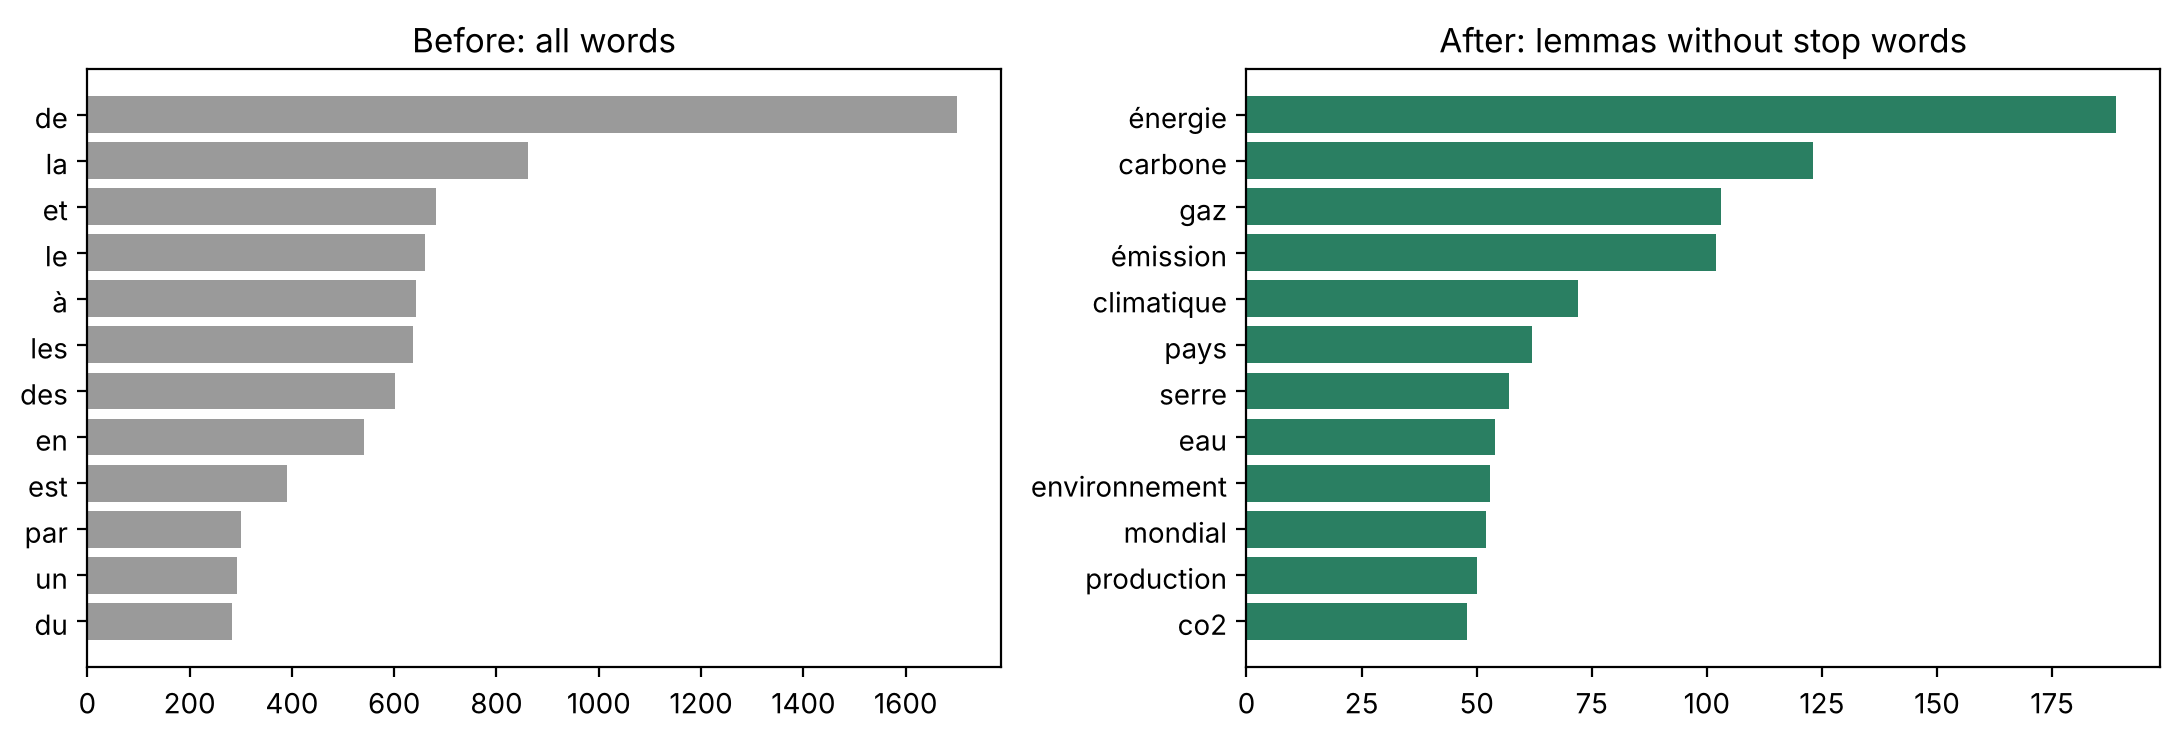

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, counter, title, color in [(ax[0], before, 'Before: all words', '#9a9a9a'), (ax[1], after, 'After: lemmas without stop words', '#2a7f62')]:
    top = counter.most_common(12)
    axis.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=color)
    axis.set_title(title)
plt.tight_layout(); plt.savefig('images/frequencies_stopwords.png', dpi=120); plt.show()

**Results.**
- **Before**, the 12 most frequent words are all stop words (*de* alone 1,701 times), and **50 % of all word tokens are stop words**.
- **After**, the list shows the topics of the corpus: *énergie, carbone, gaz, émission, climatique, pays, serre, eau, environnement…*

**The words that gained the most ranks:**
- ***utiliser*** jumps from rank 816 to 13;
- ***mondial*** from 219 to 10;
- ***émission*** from 199 to 4;
- ***renouvelable*** from 206 to 16.

These big jumps come mostly from **lemmatization**, not only from removing stop words: *utilisé, utilise, utilisés, utilisation…* were spread over many forms, and *émissions* (plural) was more frequent than *émission*. Stop-word removal moves every content word up by about 20–40 ranks; lemmatization adds the rest.

*article* is still in the top 20. It comes from the talk pages (*l'article*) and is a **domain stop word** for our corpus: we could add it to the list. Thanks to the lemma check in our function, *être* is no longer there (in Week 2 it was).

---
## 5. CoNLL-U files and the `conllu` library
CoNLL-U is the standard format of Universal Dependencies: one line per token with 10 tab-separated columns (ID, FORM, LEMMA, UPOS, XPOS, FEATS, HEAD, DEPREL, DEPS, MISC). Here is the start of the first test sentence:

In [12]:
print(''.join(open('data/fr_gsd-ud-test.conllu', encoding='utf-8').readlines()[:9]))
first = parse(open('data/fr_gsd-ud-test.conllu', encoding='utf-8').read())[0]
print('metadata:', first.metadata)
print('verbs in the present tense:', [t['form'] for t in first.filter(upos='VERB', feats__Tense='Pres')])

# sent_id = fr-ud-test_00001
# text = Je sens qu'entre ça et les films de médecins et scientifiques fous que nous avons déjà vus, nous pourrions emprunter un autre chemin pour l'origine.
1	Je	moi	PRON	_	Case=Nom|Emph=No|Number=Sing|Person=1|PronType=Prs	2	nsubj	_	wordform=je
2	sens	sentir	VERB	_	Mood=Ind|Number=Sing|Person=1|Tense=Pres|VerbForm=Fin	0	root	_	_
3	qu'	que	SCONJ	_	_	21	mark	_	SpaceAfter=No
4	entre	entre	ADP	_	_	5	case	_	_
5	ça	ça	PRON	_	Gender=Masc|Number=Sing|Person=3|PronType=Dem	21	obl:mod	_	_
6	et	et	CCONJ	_	_	8	cc	_	_
7	les	le	DET	_	Definite=Def|Number=Plur|PronType=Art	8	det	_	_



metadata: {'sent_id': 'fr-ud-test_00001', 'text': "Je sens qu'entre ça et les films de médecins et scientifiques fous que nous avons déjà vus, nous pourrions emprunter un autre chemin pour l'origine."}
verbs in the present tense: ['sens', 'pourrions']


In [13]:
# Our own corpus in CoNLL-U: spaCy can write it, conllu reads it back
def doc_to_conllu(doc, doc_id):
    lines = []
    for si, sent in enumerate(doc.sents, 1):
        toks = [t for t in sent if not t.is_space]
        if not toks:
            continue
        lines.append(f'# sent_id = {doc_id}-{si}')
        lines.append(f'# text = {sent.text.strip()}'.replace('\n', ' '))
        idx = {t.i: k for k, t in enumerate(toks, 1)}
        for k, t in enumerate(toks, 1):
            head = 0 if t.head.i == t.i or t.head.i not in idx else idx[t.head.i]
            feats = str(t.morph) or '_'
            misc = '_' if t.whitespace_ else 'SpaceAfter=No'
            lines.append('\t'.join([str(k), t.text, t.lemma_, t.pos_, t.tag_ or '_', feats, str(head),
                                     'root' if head == 0 else t.dep_, '_', misc]))
        lines.append('')
    return '\n'.join(lines) + '\n'

with open('data/corpus_spacy.conllu', 'w', encoding='utf-8') as f:
    for d, m in zip(docs, docs_meta):
        f.write(doc_to_conllu(d, m['file'].replace('.txt', '')))
print(round(Path('data/corpus_spacy.conllu').stat().st_size / 1e6, 1), 'MB written')

def upos_counts(path):
    with open(path, encoding='utf-8') as f:
        return Counter(t['upos'] for s in parse_incr(f) for t in s if isinstance(t['id'], int))

ours, gsd = upos_counts('data/corpus_spacy.conllu'), upos_counts('data/fr_gsd-ud-test.conllu')
table5 = pd.DataFrame({'our corpus (spaCy)': ours, 'UD French-GSD test (gold)': gsd}).fillna(0).astype(int)
for col in list(table5.columns):
    table5[col + ' %'] = (100 * table5[col] / table5[col].sum()).round(1)
table5.sort_values('our corpus (spaCy)', ascending=False)

2.1 MB written


,our corpus (spaCy),UD French-GSD test (gold),our corpus (spaCy) %,UD French-GSD test (gold) %
NOUN,7723,1870,23.5,18.7
ADP,5582,1479,17.0,14.8
DET,4250,1473,12.9,14.7
PUNCT,3878,1186,11.8,11.8
ADJ,2671,609,8.1,6.1
VERB,2475,821,7.5,8.2
ADV,1381,491,4.2,4.9
PRON,1115,552,3.4,5.5
CCONJ,1029,252,3.1,2.5
AUX,871,359,2.6,3.6


**Results.** In the treebank, `conllu` gives each sentence its metadata (`sent_id`, `text`) and lets us filter tokens by feature, e.g. the verbs in the present tense: *sens, pourrions*.

Our corpus (written by spaCy as `data/corpus_spacy.conllu`, 2.1 MB) compared with the GSD test set:
- **more nouns** (23.5 % vs 18.7 %) and **adjectives** (8.1 % vs 6.1 %);
- fewer pronouns (3.4 % vs 5.5 %), auxiliaries and proper nouns.

Our texts are **technical and encyclopedic**: long noun phrases like *émissions de gaz à effet de serre d'origine anthropique*, with little narration or dialogue. GSD mixes news, blogs and reviews.

Two cautions:
- our counts are **spaCy's predictions** (about 94.5 % accurate), while GSD is gold annotation;
- part of the PROPN gap may be spaCy's PROPN→NOUN errors seen in section 2.

---
## 6. A word of caution: when stop-word removal destroys meaning

In [14]:
from spacy.lang.fr.stop_words import STOP_WORDS as SPACY_FR
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
NLTK_FR = set(stopwords.words('french'))
print(f'spaCy: {len(SPACY_FR)} French stop words | NLTK: {len(NLTK_FR)} | in both: {len(SPACY_FR & NLTK_FR)}')
for w in ['ne', 'pas', 'non', 'plus', 'moins', 'sans', 'très', 'trop', 'peu', 'aucun', 'contre', 'été', 'être', 'fait']:
    print(f'   {w:6s} spaCy={w in SPACY_FR!s:5s} NLTK={w in NLTK_FR!s:5s}')

spaCy: 507 French stop words | NLTK: 157 | in both: 85
   ne     spaCy=True  NLTK=True 
   pas    spaCy=True  NLTK=True 
   non    spaCy=False NLTK=False
   plus   spaCy=True  NLTK=False
   moins  spaCy=True  NLTK=False
   sans   spaCy=True  NLTK=False
   très   spaCy=True  NLTK=False
   trop   spaCy=False NLTK=False
   peu    spaCy=True  NLTK=False
   aucun  spaCy=False NLTK=False
   contre spaCy=False NLTK=False
   été    spaCy=False NLTK=True 
   être   spaCy=True  NLTK=False
   fait   spaCy=True  NLTK=False


[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


In [15]:
pairs = ["Le charbon est une énergie renouvelable.",
         "Le charbon n'est pas une énergie renouvelable.",
         "Les émissions ont augmenté.",
         "Les émissions n'ont plus augmenté.",
         "Une ville sans pollution.",
         "Une ville avec trop de pollution."]
for s in pairs:
    print(f'{s:50s} -> {preprocess(nlp(s))}')

Le charbon est une énergie renouvelable.           -> ['charbon', 'énergie', 'renouvelable']
Le charbon n'est pas une énergie renouvelable.     -> ['charbon', 'énergie', 'renouvelable']
Les émissions ont augmenté.                        -> ['émission', 'augmenter']
Les émissions n'ont plus augmenté.                 -> ['émission', 'augmenter']
Une ville sans pollution.                          -> ['ville', 'pollution']
Une ville avec trop de pollution.                  -> ['ville', 'trop', 'pollution']


In [16]:
# A task-aware stop-word list: keep the words that carry negation, quantity or comparison
KEEP = {'ne', 'pas', 'non', 'plus', 'moins', 'sans', 'aucun', 'aucune', 'jamais', 'rien', 'trop', 'peu', 'très', 'contre'}
def preprocess_keep_negation(doc):
    return [t.lemma_.lower() for t in doc
            if not t.is_punct and not t.is_space and any(c.isalpha() for c in t.text)
            and (not t.is_stop or t.lower_ in KEEP or t.lemma_.lower() in KEEP)]
for s in pairs:
    print(f'{s:50s} -> {preprocess_keep_negation(nlp(s))}')

Le charbon est une énergie renouvelable.           -> ['charbon', 'énergie', 'renouvelable']
Le charbon n'est pas une énergie renouvelable.     -> ['charbon', 'ne', 'pas', 'énergie', 'renouvelable']


Les émissions ont augmenté.                        -> ['émission', 'augmenter']
Les émissions n'ont plus augmenté.                 -> ['émission', 'ne', 'plus', 'augmenter']
Une ville sans pollution.                          -> ['ville', 'sans', 'pollution']
Une ville avec trop de pollution.                  -> ['ville', 'trop', 'pollution']


**When stop-word removal is dangerous.**
- The two lists are very different: spaCy has 507 French stop words, NLTK 157, and only 85 are in both.
- **Both lists contain *ne* and *pas*.** spaCy also contains *plus, moins, sans, peu, très*.

The demonstration shows the danger:
- *"Le charbon **est** une énergie renouvelable"* and *"Le charbon **n'est pas** une énergie renouvelable"* give **exactly the same** output.
- So do *"Les émissions ont augmenté"* and *"Les émissions **n'ont plus** augmenté"*.
- *"Une ville **sans** pollution"* becomes *ville, pollution*.

For a **topic** classifier or a search engine this does not matter much: the topic stays the same. But for anything about **meaning or opinion** (fact-checking, sentiment: *"pas cher"* versus *"cher"*), it reverses the message.

Our task-aware list keeps *ne, pas, plus, sans, trop…* and the meaning survives. As the lecture says, removing stop words should be a **deliberate choice that depends on the task**, not a default. For our project (topic search and classification) the default list is acceptable, and we keep this caution in mind.